In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [31]:
# Configure matplotlib to output both SVG (vector) and PNG (raster) formats
%config InlineBackend.figure_formats = ['svg']

#### Building the dataset
A dictionary-based dataset will be constructed using the .dat files output from the simulation. Important things to consider for users: the algorithm relies on .dat files following a specific naming convention in `obs_K_{k}_r0_{r0}_seed_{seed}.dat`.

The initial dictionary can be accessed using the folder name key e.g.:

`dat_files_dict['fd_push_full_rod_dats']`

A specific data set can be retrieved using:

`dat_files_dict['fd_push_full_rod_dats'][(k,r0,seed)]`

At any time, use `.keys()` to identify the available data fields at any level in the dictionary. All dictionaries follow a similar organisation.

In [32]:
#### READ SIMULATION OUTPUTS AND APPENDS THEM TO A DICTIONARY OF DATAFRAMES
INPUT_FOLDER = 'fextensions_results'

import re

def extract_parameters_from_filename(filename):
    """
    Extract K, r0, and seed from filename.
    Adjust the regex pattern to match your naming convention.
    
    Common patterns might be:
    - K_<value>_r0_<value>_seed_<value>.dat
    - output_K<value>_r0<value>_seed<value>.dat
    """
    # Try to extract K, r0, and seed using regex
    # Adjust this pattern based on your actual naming convention
    pattern = r'K[_]?(\d+(?:\.\d+)?)[_]?.*r0[_]?(\d+(?:\.\d+)?)[_]?.*seed[_]?(\d+)'
    
    match = re.search(pattern, filename, re.IGNORECASE)
    if match:
        K = float(match.group(1))
        r0 = float(match.group(2))
        seed = int(match.group(3))
        return K, r0, seed
    
    # If pattern doesn't match, return None
    return None

# Dictionary to store data from each subfolder
dat_files_dict = {}

# Iterate through subfolders using scandir
for subfolder_entry in os.scandir(INPUT_FOLDER):
    if subfolder_entry.is_dir():
        subfolder_name = subfolder_entry.name
        dat_files_dict[subfolder_name] = {}
        
        # Iterate through files in the subfolder using scandir
        for file_entry in os.scandir(subfolder_entry.path):
            if file_entry.is_file() and file_entry.name.endswith('.dat'):
                try:
                    # Extract parameters from filename
                    params = extract_parameters_from_filename(file_entry.name)
                    
                    if params:
                        K, r0, seed = params
                        
                        # Read the .dat file
                        data = pd.read_csv(file_entry.path, sep='\s+', header=None)
                        
                        # Store with (K, r0, seed) as key
                        dat_files_dict[subfolder_name][(K, r0, seed)] = {
                            'filename': file_entry.name,
                            'data': data,
                            'K': K,
                            'r0': r0,
                            'seed': seed
                        }
                        #print(f"Loaded: {subfolder_name}/{file_entry.name} -> K={K}, r0={r0}, seed={seed}")
                    else:
                        print(f"Warning: Could not extract parameters from {file_entry.name}")
                    
                except Exception as e:
                    print(f"Error reading {file_entry.path}: {e}")
        
        # Remove empty subfolder entries
        if len(dat_files_dict[subfolder_name]) == 0:
            del dat_files_dict[subfolder_name]

# Summary
print(f"\n{'='*60}")
print(f"Summary: Found {len(dat_files_dict)} subfolders with .dat files")
print(f"{'='*60}")
for subfolder, files in dat_files_dict.items():
    print(f"{subfolder}: {len(files)} file(s)")
    # Show example parameters
    if files:
        example_key = list(files.keys())[0]
        print(f"  Example access: dat_files_dict['{subfolder}'][{example_key}]")
print(f"{'='*60}")


Summary: Found 3 subfolders with .dat files
fd_push_1qrt_rod_dats: 119 file(s)
  Example access: dat_files_dict['fd_push_1qrt_rod_dats'][(25.0, 10.0, 1)]
fd_push_full_rod_dats: 210 file(s)
  Example access: dat_files_dict['fd_push_full_rod_dats'][(25.0, 10.0, 1)]
fd_push_half_rod_dats: 120 file(s)
  Example access: dat_files_dict['fd_push_half_rod_dats'][(25.0, 10.0, 1)]


In [33]:
#### TESTING OUT DICTIONARY CONTENTS AND ACCESSIBILITY
print(dat_files_dict.keys())
test = dat_files_dict['fd_push_full_rod_dats'][(25, 3, 1)]
print(test.keys())

dict_keys(['fd_push_1qrt_rod_dats', 'fd_push_full_rod_dats', 'fd_push_half_rod_dats'])
dict_keys(['filename', 'data', 'K', 'r0', 'seed'])


#### Calculating steady state regions via manual cutoff

In [34]:
CUTOFF = 2.5e7  # 2,500,000

# Create new dictionary for steady-state filtered data
ss_dat_files_dict = {}

# Iterate through all subfolders
for subfolder_name, files_dict in dat_files_dict.items():
    ss_dat_files_dict[subfolder_name] = {}
    
    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        df = file_info['data']
        
        # Apply cutoff filter (assuming first column is step)
        # Adjust column index if your step column is different
        df_filtered = df[df.iloc[:, 0] >= CUTOFF].reset_index(drop=True)
        
        # Store filtered data with same structure
        ss_dat_files_dict[subfolder_name][(K, r0, seed)] = {
            'filename': file_info['filename'],
            'data': df_filtered,
            'K': K,
            'r0': r0,
            'seed': seed
        }
        
        #print(f"Filtered {subfolder_name} (K={K}, r0={r0}, seed={seed}): {len(df)} -> {len(df_filtered)} rows")

# Summary
print(f"\n{'='*60}")
print(f"Cutoff filtering complete!")
print(f"Applied cutoff: step >= {CUTOFF}")
print(f"Processed {sum(len(files) for files in ss_dat_files_dict.values())} datasets")
print(f"{'='*60}")


Cutoff filtering complete!
Applied cutoff: step >= 25000000.0
Processed 449 datasets


#### Computing statistics for each simulation

In [35]:
# Dictionary to store statistics for each simulation
stats_dict = {}

# Column indices (adjust based on your .dat file structure)
# Assuming columns are: [step, dist, force_mag, hbond, ...]
COL_STEP = 0
COL_DIST = 1
COL_FORCE_MAG = 2
COL_HBOND = 3

# Iterate through all subfolders
for subfolder_name, files_dict in ss_dat_files_dict.items():
    stats_dict[subfolder_name] = {}
    
    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        df = file_info['data']
        
        if len(df) == 0:
            print(f"Warning: Empty dataframe for {subfolder_name} (K={K}, r0={r0}, seed={seed})")
            continue
        
        # Extract columns as numpy arrays
        dist = df.iloc[:, COL_DIST].to_numpy()
        force_mag = df.iloc[:, COL_FORCE_MAG].to_numpy()
        hbond = df.iloc[:, COL_HBOND].to_numpy()
        
        # Calculate signed force: +|F| if dist > r0, -|F| if dist < r0
        signed_force = np.sign(dist - r0) * force_mag
        
        # Compute statistics
        stats_dict[subfolder_name][(K, r0, seed)] = {
            'K': K,
            'r0': r0,
            'seed': seed,
            'filename': file_info['filename'],
            
            # Signed force statistics
            'F_mean': signed_force.mean(),
            'F_std': signed_force.std(ddof=0),
            
            # Force magnitude statistics
            'force_mag_mean': force_mag.mean(),
            'force_mag_std': force_mag.std(ddof=0),
            
            # Distance statistics
            'dist_mean': dist.mean(),
            'dist_std': dist.std(ddof=0),
            
            # Hydrogen bond statistics
            'hbond_mean': hbond.mean(),
            'hbond_std': hbond.std(ddof=0),
            
            # Additional info
            'n_samples': len(df)
        }
        
        #print(f"Computed stats for {subfolder_name} (K={K}, r0={r0}, seed={seed}): {len(df)} samples")

# Summary
print(f"\n{'='*60}")
print(f"Statistics computation complete!")
print(f"Processed {sum(len(files) for files in stats_dict.values())} datasets")
print(f"{'='*60}")


Statistics computation complete!
Processed 449 datasets


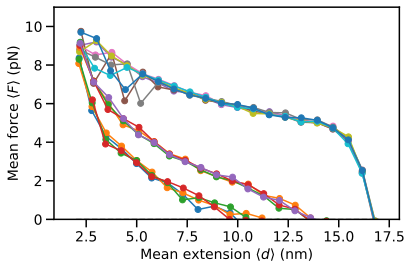

In [36]:
# Unit conversion factors
DIST_CONVERSION = 0.8  # to nm
FORCE_CONVERSION = 48.6  # to pN

plt.rcParams.update({
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 8,
    "ytick.major.size": 8,
    "font.size": 14,
    "axes.labelsize": 14,
})

fig, ax = plt.subplots(figsize=(6, 4))

ax.hlines(0, xmin=2, xmax=17, colors='gray', linestyles='dashed', alpha=0.7)

# Collect all data points organized by subfolder, K, and seed
for subfolder_name, files_dict in stats_dict.items():
    # Organize data by (K, seed) for proper plotting
    data_by_k_seed = {}
    
    for (K, r0, seed), stats in files_dict.items():
        key = (K, seed)
        if key not in data_by_k_seed:
            data_by_k_seed[key] = []
        
        # Append (r0, dist_mean, F_mean) for this simulation
        data_by_k_seed[key].append({
            'r0': r0,
            'dist_mean': stats['dist_mean'],
            'F_mean': stats['F_mean']
        })
    
    # Plot each (K, seed) combination
    for (K, seed), data_points in data_by_k_seed.items():
        # Sort by mean distance for connected lines
        data_points = sorted(data_points, key=lambda x: x['dist_mean'])
        
        # Extract values
        dist_means = [DIST_CONVERSION * d['dist_mean'] for d in data_points]
        F_means = [FORCE_CONVERSION * d['F_mean'] for d in data_points]
        
        # Plot with label
        ax.plot(dist_means, F_means, marker='o', 
                label=f"{subfolder_name}, K={K}, seed={seed}", 
                linewidth=1.5, markersize=6)


ax.set_xlabel(r"Mean extension $\langle d \rangle$ (nm)", fontsize=14)
ax.set_ylabel(r"Mean force $\langle F \rangle$ (pN)", fontsize=14)
#ax.legend(fontsize=10, bbox_to_anchor=(1.05, 1), loc='best')
#ax.grid(True, alpha=0.3)
ax.set_xlim(None, 18)
ax.set_ylim(0, 11)

plt.tight_layout()
plt.show()

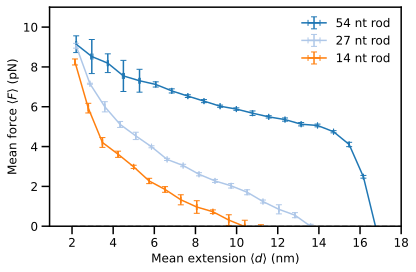

In [ ]:
#### Aggregate means and error bars across seeds (per K, r0)
from collections import defaultdict
import numpy as np
from matplotlib import colormaps

#cmap = colormaps['tab20']  # Use a categorical colormap for distinct colors

def aggregate_by_category(stats_dict, include_substr):
    grouped = defaultdict(list)
    for subfolder_name, files_dict in stats_dict.items():
        if include_substr not in subfolder_name.lower():
            continue
        for (K, r0, seed), stats in files_dict.items():
            grouped[(K, r0)].append(stats)

    aggregated = []
    for (K, r0), entries in grouped.items():
        dist_vals = np.array([e['dist_mean'] for e in entries])
        force_vals = np.array([e['F_mean'] for e in entries])
        dist_mean = dist_vals.mean()
        force_mean = force_vals.mean()

        # Error bars: standard deviation across seeds (use ddof=1 when possible)
        ddof = 1 if len(entries) > 1 else 0
        dist_err = dist_vals.std(ddof=ddof)
        force_err = force_vals.std(ddof=ddof)

        aggregated.append({
            'K': K,
            'r0': r0,
            'dist_mean': dist_mean,
            'F_mean': force_mean,
            'dist_err': dist_err,
            'F_err': force_err,
            'n': len(entries)
        })

    return sorted(aggregated, key=lambda x: x['dist_mean'])

# Define rod configurations: (substring, label, color)
ROD_CONFIGS = [
    ('full', '54 nt rod', 'blue'),
    ('half', '27 nt rod', 'red'),
    ('1qrt', '14 nt rod', 'green'),
    # Add more rod types here as needed
]

# Aggregate data for each rod type
aggregated_data = {}
for substr, label, color in ROD_CONFIGS:
    aggregated_data[substr] = aggregate_by_category(stats_dict, substr)

plt.rcParams.update({
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 8,
    "ytick.major.size": 8,
    "font.size": 12,
    "axes.labelsize": 12,
    "legend.fontsize": 12,
})

fig, ax = plt.subplots(figsize=(6, 4))

# Determine x-axis range from all data
all_dist_means = []
for agg_data in aggregated_data.values():
    all_dist_means.extend([DIST_CONVERSION * d['dist_mean'] for d in agg_data])

if all_dist_means:
    ax.hlines(0, xmin=2, xmax=max(all_dist_means), colors='gray', linestyles='dashed', alpha=0.7)

# Plot trajectory for each rod type
for substr, label, color in ROD_CONFIGS:
    agg = aggregated_data[substr]
    if agg:
        x = [DIST_CONVERSION * d['dist_mean'] for d in agg]
        y = [FORCE_CONVERSION * d['F_mean'] for d in agg]
        xerr = [DIST_CONVERSION * d['dist_err'] for d in agg]
        yerr = [FORCE_CONVERSION * d['F_err'] for d in agg]
        ax.errorbar(x, y, xerr=xerr, yerr=yerr, marker=None, linestyle='-',
                    linewidth=1.5, markersize=6, capsize=3, label=label,
                    color=color)

ax.set_xlabel(r"Mean extension $\langle d \rangle$ (nm)")
ax.set_ylabel(r"Mean force $\langle F \rangle$ (pN)")
ax.set_xlim(None, 18)
ax.set_ylim(0, 11)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()
